Use this script to plot all my thesis figures! I used Jupyter Notebook (Python 3.12.11)

## 1. Imports and figure settings

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import (
    LinearSegmentedColormap, ListedColormap,
    BoundaryNorm, Normalize
)
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, ScalarFormatter
from IPython.display import display

from sswm import SM_C_H
from param import get_baseline_params, full_param_name_list
from growth import LAIGrowth

DATA_FILE = Path('Sites_Data.csv')
FIGURE_DIR = Path('figures')
FIGURE_DIR.mkdir(exist_ok=True)

SITES_ORDER = ('US-Fmf', 'CA-TP4', 'FR-Pue', 'FI-Hyy')
THINNING = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5)
THIN_COLORS = ('#222222', '#65BDBA', '#B0D6A9', '#FDCD94', '#FAA26F', '#FC757B')
THIN_COLOR = dict(zip(THINNING, THIN_COLORS))

YEARS = 50
NBINS = 100                
GROWTH_EXPONENT = 1       
SAVE_FIGURES = True

print('Working directory:', Path.cwd())
OUTPUTS = ('mean_s', 'ET', 'T', 'E')


Working directory: /Users/wandifeng/Desktop/Final Thesis Script


## 2. Load site information from `Sites_Data.csv`

The CSV has one parameter row for each site, interleaved with citation rows. Only the site rows are used!

In [2]:
def load_sites(csv_file='Sites_Data.csv'):

    csv_file = Path(csv_file)
    if not csv_file.exists():
        raise FileNotFoundError(f'{csv_file} not found. Put the CSV beside the notebook.')
    df = pd.read_csv(csv_file, encoding='utf-8-sig', dtype={'FLUXNET site': str})
    df.columns = df.columns.str.strip()
    df = df.loc[df['FLUXNET site'].isin(SITES_ORDER)].copy()
    if df['FLUXNET site'].duplicated().any() or set(df['FLUXNET site']) != set(SITES_ORDER):
        raise ValueError('Sites_Data.csv must contain exactly one row per site: ' + ', '.join(SITES_ORDER))
    soil_col = next((c for c in df.columns if c.startswith('Soil Texture:')))
    cols = {'soil_i': soil_col, 'T_GS': 'G_S length', 'rf_alpha': 'G_S Ave_P_intensity_d (m event^-1)', 'rf_lambda': 'G_S Ave_P_freq_d (day^-1)', 'Eo': 'G_S Ave_PET_d (m day^-1)', 'ET_obs': 'G_S Ave_ET_d (m day^-1)', 'hc': 'Canopy Height (m)', 'RAI': 'RAI (m^2 m^-2)', 'Zm': 'Zr (m)', 'beta': 'beta', 'ref_LAI': 'LAI_0', 'Pg50': 'Pg_50 (MPa)', 'Px50': 'Px_50 (MPa)', 'k_xl_max': 'k_xl_max (kg/m/s/MPa)'}
    sites = {}
    for _, r in df.iterrows():
        d = {key: float(pd.to_numeric(r[column], errors='raise')) for key, column in cols.items()}
        d['soil_i'] = int(d['soil_i'])
        d['species'] = str(r['Species'])
        code = r['FLUXNET site']
        if not all((np.isfinite(v) for key, v in d.items() if key != 'species')):
            raise ValueError(f'{code}: missing/nonfinite model parameter')
        if not (0 <= d['soil_i'] <= 6 and 0 < d['beta'] < 1 and (d['ref_LAI'] > 0)):
            raise ValueError(f'{code}: invalid soil class, turnover, or LAI')
        sites[code] = d
    return {code: sites[code] for code in SITES_ORDER}

SITES = load_sites(DATA_FILE)
site_table = pd.DataFrame(SITES).T
site_table.index.name = 'Site'
display(site_table[['ref_LAI', 'T_GS', 'beta', 'rf_alpha',
                    'rf_lambda', 'Eo', 'ET_obs', 'Zm', 'RAI']])

,ref_LAI,T_GS,beta,rf_alpha,rf_lambda,Eo,ET_obs,Zm,RAI
Site,,,,,,,,,
US-Fmf,1.5,109.0,0.25,0.006529,0.344037,0.004843,0.001886,0.45,11.0
CA-TP4,5.0,109.0,0.4,0.006307,0.530442,0.004636,0.002334,0.45,11.0
FR-Pue,2.2,106.0,0.35,0.007305,0.268302,0.004299,0.001902,0.45,11.6
FI-Hyy,2.2,78.0,0.25,0.005132,0.500916,0.003473,0.002138,0.45,4.6


## 3. Ecohydrological model and calibration of maximum growth rate

Please refer to Section 2.3.1.5 of thesis to see how g+ is calibrated!


In [3]:
def parameter_dict(site, lai):
    p = get_baseline_params(soil_i=site['soil_i']).copy()
    for name in ('T_GS', 'rf_alpha', 'rf_lambda', 'Eo', 'hc', 'RAI', 'Zm', 'Pg50', 'Px50', 'k_xl_max'):
        p[name] = site[name]
    p['LAI'] = float(lai)
    return p

#p(ss)
def soil_model(params, nbins=100):
    with np.errstate(invalid='ignore', divide='ignore', over='ignore', under='ignore'):
        sm = SM_C_H([params[k] for k in full_param_name_list], nbins=nbins, f_wilt=0.05, f_star=0.95, constraints=False)
    p0 = np.asarray(sm.p0, dtype=float)
    if not np.all(np.isfinite(p0)) or np.any(p0 < 0) or (not np.isclose(p0.sum(), 1.0, atol=1e-06)) or (not np.isfinite(sm.s_wilt)) or (not np.isfinite(sm.s_star)) or (not sm.s_wilt < sm.s_star):
        raise ValueError('Invalid stationary soil-moisture distribution or growth thresholds')
    return sm

#<T>, <E>, <ET> 
def hydraulic_outputs(params, nbins=100, include_pdf=False):
    sm = soil_model(params, nbins)
    p0 = np.asarray(sm.p0, dtype=float)
    grid = np.linspace(0, 1, len(p0))
    et = float(sm.get_mean_et(p0)) * 1000
    t = float(sm.get_mean_t(p0)) * 1000
    e = et - t
    result = {'mean_s': float(np.sum(grid * p0)), 'ET': et, 'T': t, 'E': e, 'I': float(sm.rf_alpha * sm.rf_lambda * -np.expm1(-sm.delta / sm.rf_alpha) * 1000), 'Emax': float(sm.E_max * sm.n * sm.Zm * 1000), 'Tww': float(sm.T_ww * sm.n * sm.Zm * 1000), 's_h': sm.s_h, 's_fc': sm.s_fc, 's_wilt': sm.s_wilt, 's_star': sm.s_star, 'model_ok': int(sm.et_ok)}
    if include_pdf:
        result['p0'] = p0.copy()
    if not np.all(np.isfinite([result[k] for k in OUTPUTS])):
        raise ValueError('Non-finite mean saturation or ET components')
    if min(et, t, e) < -1e-07:
        raise ValueError('Negative modeled water flux')
    return (result, sm)

#<g>
def mean_growth(sm, g_plus, season_days, growth_exponent=1):  
    #xi=s*, s_tilde=s_wilt 
    lai = LAIGrowth(sm, g_plus=g_plus, a=growth_exponent, xi=sm.s_star, s_tilde=sm.s_wilt, b0=sm.LAI, Tg=season_days)
    return (float(lai.mean_g()), float(lai.lai_increment()))

#g+
def calibrate_gplus(sites, nbins=100, growth_exponent=1):    
    values = {}
    for code, site in sites.items():
        params = parameter_dict(site, site['ref_LAI'])
        sm = soil_model(params, nbins)
        _, unit_increment = mean_growth(sm, 1.0, site['T_GS'], growth_exponent)
        if not np.isfinite(unit_increment) or unit_increment <= 0:
            raise ValueError(f'{code}: cannot calibrate g+ (nonpositive unit growth)')
        values[code] = site['beta'] * site['ref_LAI'] / unit_increment
    return values

G_PLUS_BACKCALC = calibrate_gplus(SITES, nbins=NBINS, growth_exponent=GROWTH_EXPONENT)
display(pd.DataFrame({'Site': list(G_PLUS_BACKCALC),
                      'g_plus': list(G_PLUS_BACKCALC.values())}).set_index('Site'))

,g_plus
Site,
US-Fmf,0.007799
CA-TP4,0.025801
FR-Pue,0.021318
FI-Hyy,0.011170


## 4. Run the 50-year simulation

Six initial LAI reductions (0%, 10%, 20%, 30%, 40%, 50%); site-average meteorology is fixed during each simulation. Each year updates LAI and recalculates stationary $p(s)$, $\langle s\rangle$, $\langle ET\rangle$, $\langle T\rangle$, $\langle E\rangle$, and $\langle g \rangle$.

In [4]:
def simulate(sites, gplus, years=50, thinning=THINNING, nbins=100, growth_exponent=1):
    results = {}
    for code, site in sites.items():
        results[code] = {}
        for fraction in thinning:
            lai = site['ref_LAI'] * (1 - fraction)
            rows = []
            for year in range(years + 1):
                out, sm = hydraulic_outputs(parameter_dict(site, lai), nbins, include_pdf=True)
                g, inc = mean_growth(sm, gplus[code], site['T_GS'], growth_exponent)
                lai_next = (1 - site['beta']) * lai + inc
                rows.append({'year': year, 'LAI': lai, 'dLAI': lai_next - lai, 'growth': inc, 'mean_g': g, **out})
                lai = lai_next
            results[code][fraction] = pd.DataFrame(rows)
    return results

ALL_RESULTS = simulate(SITES, G_PLUS_BACKCALC, years=YEARS,
                       thinning=THINNING, nbins=NBINS,
                       growth_exponent=GROWTH_EXPONENT)
for site in SITES_ORDER:
    d = ALL_RESULTS[site][0.0]
    assert np.allclose(d['LAI'], SITES[site]['ref_LAI'], rtol=1e-8)


rows = []
for site, scenarios in ALL_RESULTS.items():
    for thinning, df in scenarios.items():
        t = df.drop(columns='p0').copy()
        t.insert(0, 'thinning', thinning)
        t.insert(0, 'site', site)
        rows.append(t)
pd.concat(rows, ignore_index=True).to_csv('thinning_simulations.csv', index=False)

## 5. Figure 1. Simulated soil saturation probability density functions over 50 years. 


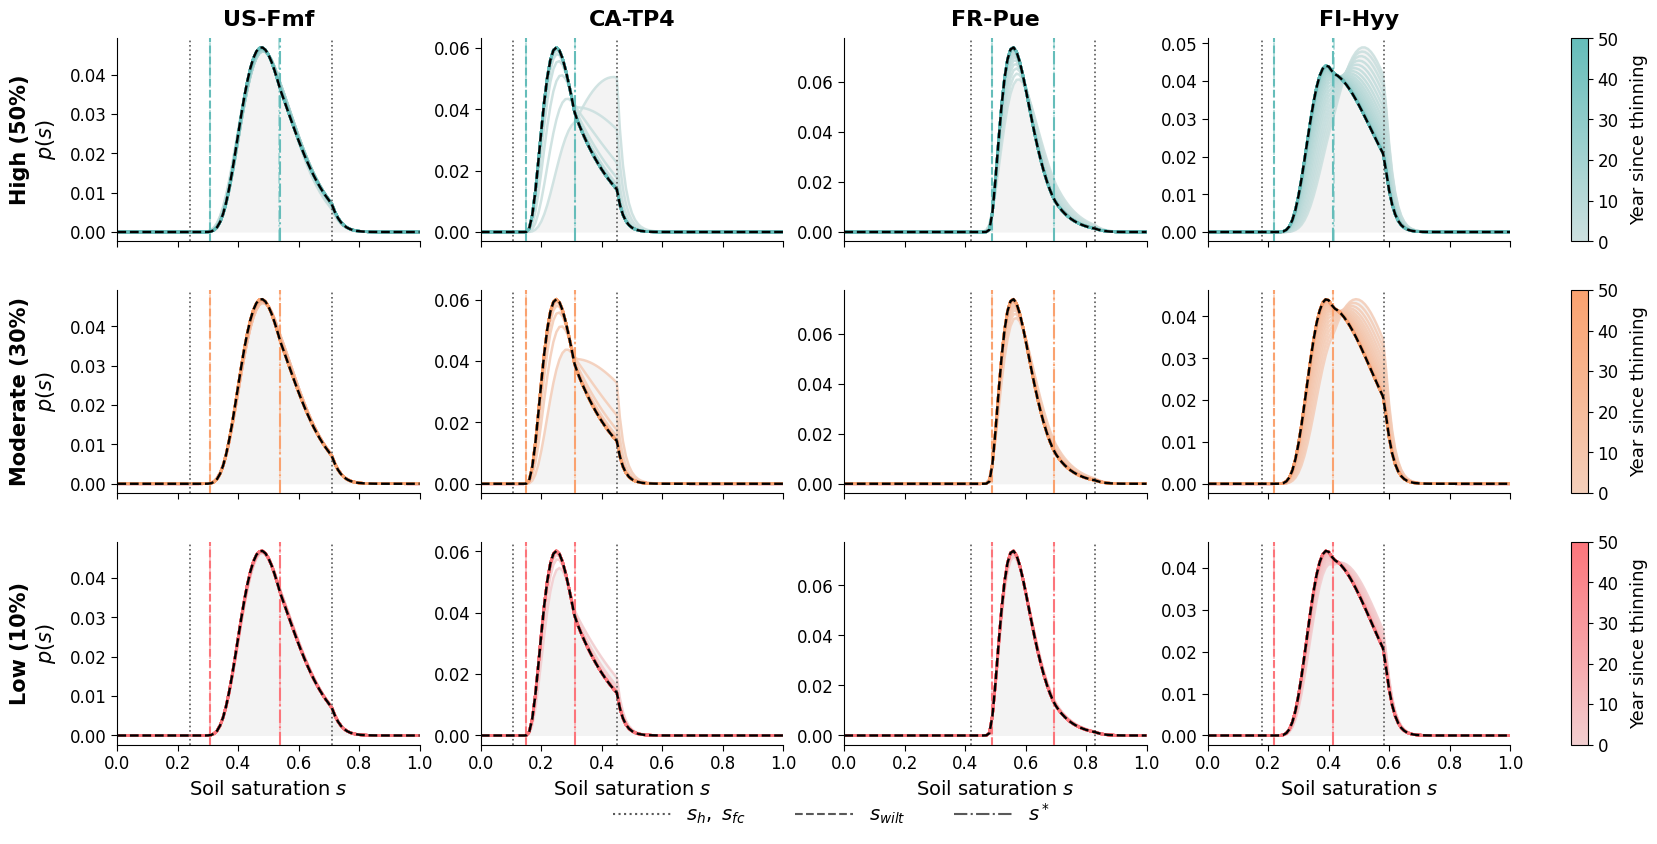

In [5]:

scenario_rows = [
    (0.50, 'High (50%)', '#65BDBA'),
    (0.30, 'Moderate (30%)', '#FAA26F'),
    (0.10, 'Low (10%)', '#FC757B'),
]

fig = plt.figure(figsize=(4.0 * len(SITES_ORDER) + 1.0,
                          3.0 * len(scenario_rows)))
gs = GridSpec(
    len(scenario_rows), len(SITES_ORDER) + 1,
    width_ratios=[1] * len(SITES_ORDER) + [0.055],
    hspace=0.24, wspace=0.25, figure=fig,
)
year_norm = Normalize(vmin=0, vmax=YEARS)

for row, (thin, scenario, base_color) in enumerate(scenario_rows):
    original_cmap = LinearSegmentedColormap.from_list(
        f'thin_original_{row}', ['#efecec', base_color]
    )
    start_color = 0.40 if thin == 0.30 else 0.25
    cmap_yr = LinearSegmentedColormap.from_list(
        f'thin_{row}', original_cmap(np.linspace(start_color, 1.0, 256))
    )

    for col, site_code in enumerate(SITES_ORDER):
        ax = fig.add_subplot(gs[row, col])
        d_ref = ALL_RESULTS[site_code][0.0]
        d = ALL_RESULTS[site_code][thin]
        s_plot = np.linspace(0, 1, len(d.iloc[0]['p0']))
        p0_ref = np.asarray(d_ref.iloc[-1]['p0'], dtype=float)
        p0_first = np.asarray(d.iloc[0]['p0'], dtype=float)
 
        ax.fill_between(s_plot, 0, p0_first,
                        where=np.isfinite(p0_first), color='#EBEBEB',
                        alpha=0.6, linewidth=0, zorder=0)

        ax.plot(s_plot, p0_ref, color='black', lw=1.7,
                ls='--', zorder=10)

        for _, r in d.iterrows():
            p0 = np.asarray(r['p0'], dtype=float)
            if not np.all(np.isfinite(p0)):
                continue
            ax.plot(s_plot, p0, color=cmap_yr(year_norm(r['year'])),
                    lw=1.8, alpha=0.9)

        for value in [d.iloc[0]['s_h'], d.iloc[0]['s_fc']]:
            ax.axvline(value, color='0.35', ls=':', lw=1.2, zorder=5)

        for key, style in [('s_wilt', '--'), ('s_star', '-.')]:
            ax.axvline(d.iloc[0][key], color=base_color,
                       ls=style, lw=1.3, alpha=0.5, zorder=6)
            ax.axvline(d_ref.iloc[-1][key], color=base_color,
                       ls=style, lw=1.5, zorder=6)

        ax.set_xlim(0, 1)
        ax.tick_params(axis='both', labelsize=12, length=4)
        if col == 0:
            ax.set_ylabel(f'{scenario}\n$p(s)$', fontsize=15,
                          fontweight='bold', labelpad=9)
        if row == 0:
            ax.set_title(site_code, fontsize=16, fontweight='bold', pad=9)
        if row == len(scenario_rows) - 1:
            ax.set_xlabel(r'Soil saturation $s$', fontsize=14, labelpad=5)
        else:
            ax.tick_params(axis='x', labelbottom=False)
        ax.spines[['top', 'right']].set_visible(False)

 
    cax = fig.add_subplot(gs[row, -1])
    sm_cbar = plt.cm.ScalarMappable(cmap=cmap_yr, norm=year_norm)
    cbar = fig.colorbar(sm_cbar, cax=cax)
    cbar.set_label('Year since thinning', fontsize=13, labelpad=8)
    cbar.ax.tick_params(labelsize=12)

threshold_handles = [
    Line2D([0], [0], color='0.35', ls=':', lw=1.5, label=r'$s_h,\ s_{fc}$'),
    Line2D([0], [0], color='0.35', ls='--', lw=1.5, label=r'$s_{wilt}$'),
    Line2D([0], [0], color='0.35', ls='-.', lw=1.5, label=r'$s^*$'),
]
fig.legend(handles=threshold_handles, ncol=3, fontsize=14, frameon=False,
           loc='lower center', bbox_to_anchor=(0.5, 0.005),
           handlelength=3, columnspacing=2.5)
fig.subplots_adjust(left=0.08, right=0.945, top=0.90, bottom=0.115)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / 'Fig1_Soil_PDF.png', dpi=200, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / 'Fig1_Soil_PDF.pdf', bbox_inches='tight')
plt.show()

## 6. Figure 2. Percent changes in mean soil saturation over 50 years

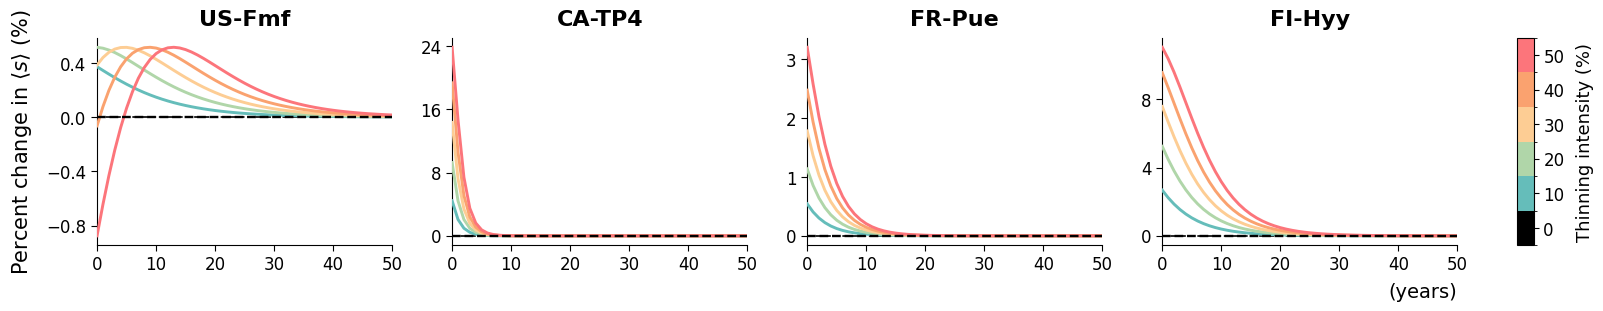

In [6]:
ORIGINAL_TREATMENT_NAMES = {
    0.0: 'Unthinned',
    0.1: 'Low (10%)',
    0.2: 'Moderate-low (20%)',
    0.3: 'Moderate (30%)',
    0.4: 'Moderate-high (40%)',
    0.5: 'High (50%)',
}
COLORS = {ORIGINAL_TREATMENT_NAMES[f]: THIN_COLOR[f] for f in THINNING}
all_results = {
    site: {ORIGINAL_TREATMENT_NAMES[f]: ALL_RESULTS[site][f] for f in THINNING}
    for site in SITES_ORDER
}
N_YEARS = YEARS

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 15,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
})

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator

plot_scenarios = [
    ('Unthinned',            0, 'black'),
    ('Low (10%)',          10, COLORS['Low (10%)']),
    ('Moderate-low (20%)',  20, COLORS['Moderate-low (20%)']),
    ('Moderate (30%)',      30, COLORS['Moderate (30%)']),
    ('Moderate-high (40%)', 40, COLORS['Moderate-high (40%)']),
    ('High (50%)',          50, COLORS['High (50%)']),
]

fig = plt.figure(figsize=(4.0 * len(SITES) + 1.0, 3.4))

gs = GridSpec(
    1,
    len(SITES) + 1,
    width_ratios=[1] * len(SITES) + [0.055],
    wspace=0.25,
    figure=fig,
)

for col, site_code in enumerate(SITES):
    ax = fig.add_subplot(gs[0, col])

    d_ref = all_results[site_code]['Unthinned']
    ref_mean_s = float(d_ref['mean_s'].iloc[-1])

    if not np.isfinite(ref_mean_s) or np.isclose(ref_mean_s, 0):
        raise ValueError(
            f'{site_code}: reference mean soil saturation '
            'must be finite and nonzero.'
        )

    ax.axhline(
        0, color='black', lw=1.2, ls='--', zorder=2
    )

    for scenario, thinning_pct, color in plot_scenarios:
        d = all_results[site_code][scenario]

        pct_change = (
            100 * (d['mean_s'].to_numpy() - ref_mean_s)
            / ref_mean_s
        )

        ax.plot(
            d['year'].to_numpy(),
            pct_change,
            color=color,
            lw=1.7 if thinning_pct == 0 else 2.1,
            ls='--' if thinning_pct == 0 else '-',
            zorder=5 if thinning_pct == 0 else 3,
        )

    ax.set_title(
        site_code,
        fontsize=16,
        fontweight='bold',
        pad=9,
    )

    if col == len(SITES) - 1:
        ax.set_xlabel(
            '(years)',
            fontsize=14,
            labelpad=6,
            loc='right',
        )

    ax.set_xlim(0, N_YEARS)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.tick_params(axis='both', labelsize=12, length=4)

    if col == 0:
        ax.set_ylabel(
            r'Percent change in $\langle s \rangle$ (%)',
            fontsize=15,
            labelpad=9,
        )

    ax.spines[['top', 'right']].set_visible(False)

cmap = ListedColormap([
    color for _, _, color in plot_scenarios
])
boundaries = np.arange(-5, 56, 10)
norm = BoundaryNorm(boundaries, cmap.N)

cax = fig.add_subplot(gs[0, -1])
sm_cbar = plt.cm.ScalarMappable(cmap=cmap, norm=norm)

cbar = fig.colorbar(
    sm_cbar,
    cax=cax,
    boundaries=boundaries,
    ticks=[0, 10, 20, 30, 40, 50],
    spacing='uniform',
)
cbar.set_label(
    'Thinning intensity (%)',
    fontsize=13,
    labelpad=8,
)
cbar.ax.tick_params(labelsize=12)

fig.subplots_adjust(
    left=0.10,
    right=0.945,
    top=0.85,
    bottom=0.24,
)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / 'Fig2_Mean_Soil_Saturation.png', dpi=200, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / 'Fig2_Mean_Soil_Saturation.pdf', bbox_inches='tight')
plt.show()

## 7. Figure 3. Simulated water fluxes over 50 years following forest thinning

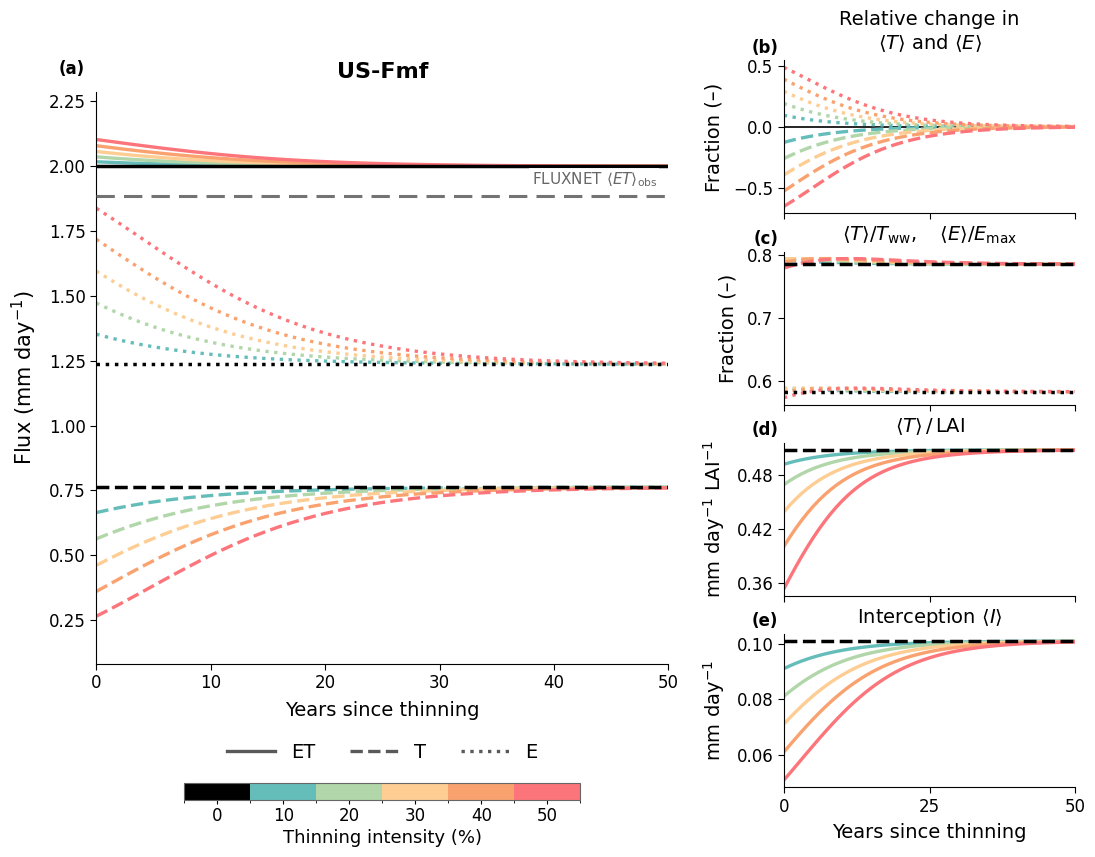

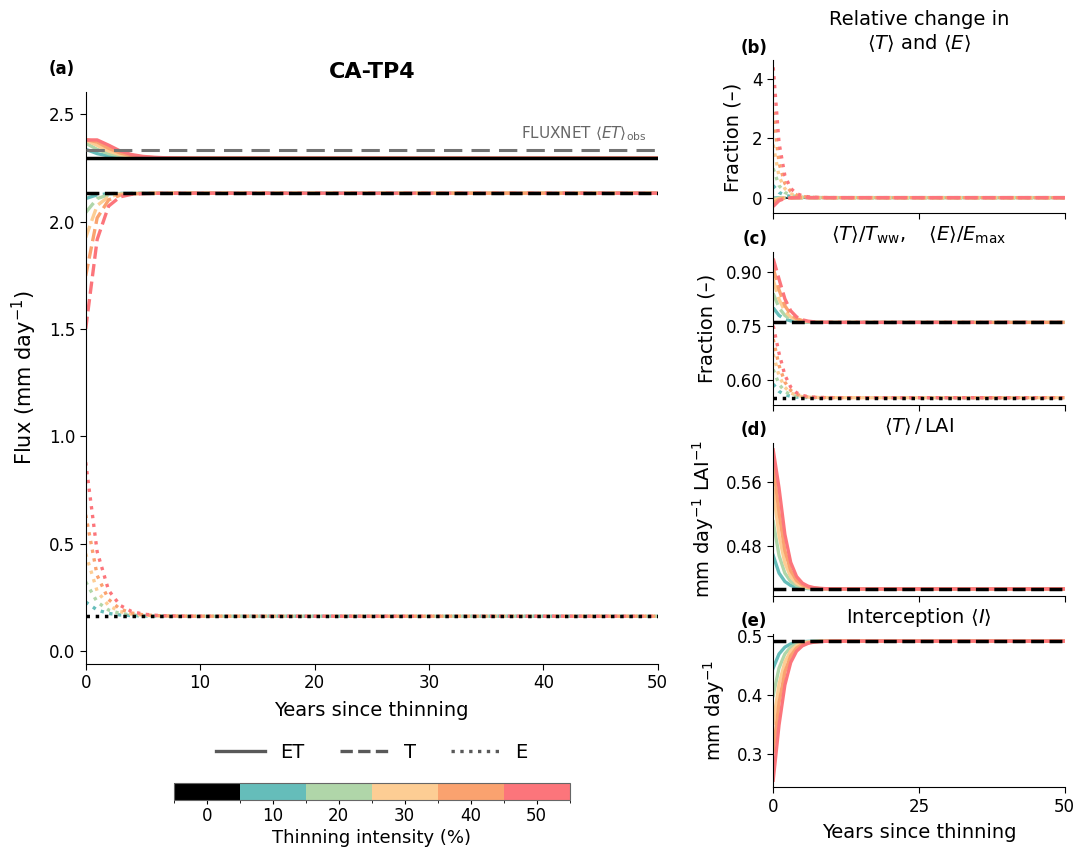

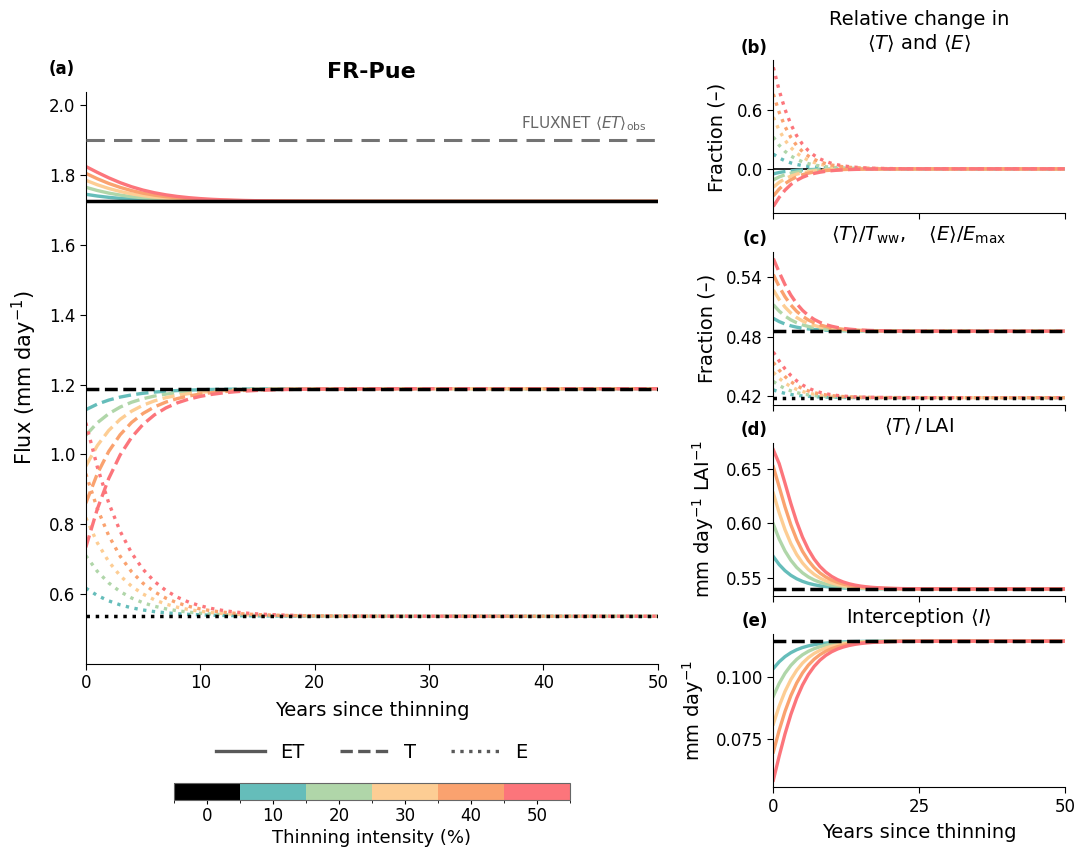

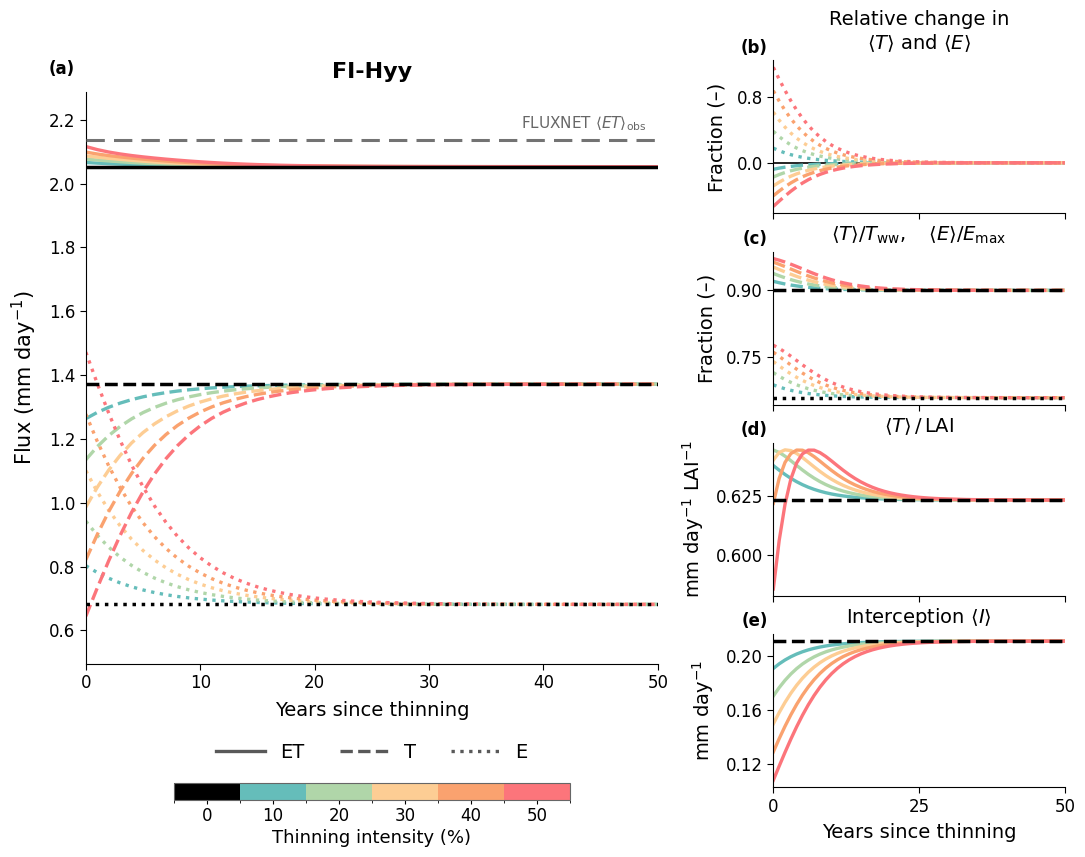

In [7]:

scenarios = []

for scenario, color in COLORS.items():
    if scenario == "Unthinned":
        continue

    match = re.search(r"(\d+(?:\.\d+)?)\s*%", scenario)

    if match is None:
        raise ValueError(
            f"Cannot identify thinning percentage in {scenario!r}."
        )

    scenarios.append((float(match.group(1)), scenario, color))

scenarios.sort(key=lambda item: item[0])

if not scenarios:
    raise ValueError("COLORS must contain at least one thinning scenario.")


levels = np.array([0.0] + [item[0] for item in scenarios])
scenario_colors = ["black"] + [item[2] for item in scenarios]

boundaries = np.concatenate([
    [levels[0] - (levels[1] - levels[0]) / 2],
    (levels[:-1] + levels[1:]) / 2,
    [levels[-1] + (levels[-1] - levels[-2]) / 2],
])

cmap = ListedColormap(scenario_colors)
norm = BoundaryNorm(boundaries, cmap.N)

LINE_WIDTH = 2.4
REFERENCE_WIDTH = 2.5
TITLE_SIZE = 16
LABEL_SIZE = 14
TICK_SIZE = 12

flux_styles = {
    "ET": "-",
    "T": "--",
    "E": ":",
}

figures = {}

with plt.rc_context({"font.family": "DejaVu Sans"}):

    for site_code in SITES:

        fig = plt.figure(figsize=(11, 8.5))
        figures[site_code] = fig
        
        ax_main = fig.add_axes([0.085, 0.220, 0.520, 0.673])
        ax_rel = fig.add_axes([0.710, 0.750, 0.265, 0.180])

        ax_ratio = fig.add_axes(
            [0.710, 0.525, 0.265, 0.180],
            sharex=ax_rel,
        )

        ax_tlai = fig.add_axes(
            [0.710, 0.300, 0.265, 0.180],
            sharex=ax_rel,
        )

        ax_i = fig.add_axes(
            [0.710, 0.075, 0.265, 0.180],
            sharex=ax_rel,
        )

        d_ref = (
            all_results[site_code]["Unthinned"]
            .sort_values("year")
        )

        ref_by_year = d_ref.set_index("year")
        years_ref = d_ref["year"].to_numpy(dtype=float)

        # ------------------------------------------------------------
        # Thinning scenarios
        # ------------------------------------------------------------
        for intensity, scenario, color in scenarios:

            d = (
                all_results[site_code][scenario]
                .sort_values("year")
            )

            years = d["year"].to_numpy(dtype=float)

            if not np.all(np.isin(years, ref_by_year.index)):
                raise ValueError(
                    f"Missing reference years for {site_code}: {scenario}"
                )

            reference = ref_by_year.reindex(years)

            # (a) ET, T, and E
            for variable, style in flux_styles.items():
                ax_main.plot(
                    years,
                    d[variable].to_numpy(dtype=float),
                    color=color,
                    ls=style,
                    lw=LINE_WIDTH,
                )

            # (b) Relative changes compared with the unthinned reference
            for variable, style in [("T", "--"), ("E", ":")]:
                values = d[variable].to_numpy(dtype=float)
                baseline = reference[variable].to_numpy(dtype=float)

                ax_rel.plot(
                    years,
                    (values - baseline) / baseline,
                    color=color,
                    ls=style,
                    lw=LINE_WIDTH,
                )

            # (c) Fractions of each scenario's own maximum rates realized
            ax_ratio.plot(
                years,
                d["T"] / d["Tww"],
                color=color,
                ls="--",
                lw=LINE_WIDTH,
            )

            ax_ratio.plot(
                years,
                d["E"] / d["Emax"],
                color=color,
                ls=":",
                lw=LINE_WIDTH,
            )

            # (d) Transpiration per unit LAI
            ax_tlai.plot(
                years,
                d["T"] / d["LAI"],
                color=color,
                lw=LINE_WIDTH,
            )

            # (e) Interception
            ax_i.plot(
                years,
                d["I"].to_numpy(dtype=float),
                color=color,
                lw=LINE_WIDTH,
            )

        # ------------------------------------------------------------
        # Unthinned reference
        # ------------------------------------------------------------
        for variable, style in flux_styles.items():
            ax_main.plot(
                years_ref,
                d_ref[variable].to_numpy(dtype=float),
                color="black",
                ls=style,
                lw=REFERENCE_WIDTH,
                zorder=10,
            )

        ax_rel.axhline(
            0,
            color="black",
            lw=1.2,
            zorder=0,
        )

        # Reference fractions for panel (c).
        ax_ratio.plot(
            years_ref,
            d_ref["T"] / d_ref["Tww"],
            color="black",
            ls="--",
            lw=REFERENCE_WIDTH,
            zorder=10,
        )

        ax_ratio.plot(
            years_ref,
            d_ref["E"] / d_ref["Emax"],
            color="black",
            ls=":",
            lw=REFERENCE_WIDTH,
            zorder=10,
        )

        ax_tlai.plot(
            years_ref,
            d_ref["T"] / d_ref["LAI"],
            color="black",
            ls="--",
            lw=REFERENCE_WIDTH,
            zorder=10,
        )

        ax_i.plot(
            years_ref,
            d_ref["I"].to_numpy(dtype=float),
            color="black",
            ls="--",
            lw=REFERENCE_WIDTH,
            zorder=10,
        )

        # ------------------------------------------------------------
        # Observed FLUXNET ET
        # ------------------------------------------------------------
        et_obs_mm = 1000.0 * float(SITES[site_code]["ET_obs"])

        if np.isfinite(et_obs_mm):
            ax_main.axhline(
                et_obs_mm,
                color="0.45",
                ls=(0, (6, 3)),
                lw=2.2,
                zorder=12,
            )

            ax_main.annotate(
                r"FLUXNET $\langle ET\rangle_{\mathrm{obs}}$",
                xy=(0.98, et_obs_mm),
                xycoords=("axes fraction", "data"),
                xytext=(0, 5),
                textcoords="offset points",
                ha="right",
                va="bottom",
                fontsize=11,
                color="0.40",
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.85,
                    pad=1.5,
                ),
                zorder=15,
            )

        # ------------------------------------------------------------
        # Titles and axis labels
        # ------------------------------------------------------------
        ax_main.set_title(
            site_code,
            fontsize=TITLE_SIZE,
            fontweight="bold",
            pad=10,
        )
        ax_main.set_xlabel(
            "Years since thinning",
            fontsize=LABEL_SIZE,
            labelpad=6,
        )
        ax_main.set_ylabel(
            r"Flux (mm day$^{-1}$)",
            fontsize=15,
            labelpad=7,
        )
        ax_main.margins(y=0.10)

        ax_rel.set_title(
            "Relative change in\n"
            r"$\langle T\rangle$ and $\langle E\rangle$",
            fontsize=LABEL_SIZE,
            pad=8,
        )
        ax_rel.set_ylabel(
            "Fraction (–)",
            fontsize=LABEL_SIZE,
            labelpad=7,
        )

        ax_ratio.set_title(
            r"$\langle T\rangle/T_{\mathrm{ww}},"
            r"\quad \langle E\rangle/E_{\max}$",
            fontsize=LABEL_SIZE,
            pad=8,
        )
        ax_ratio.set_ylabel(
            "Fraction (–)",
            fontsize=LABEL_SIZE,
            labelpad=7,
        )

        ax_tlai.set_title(
            r"$\langle T\rangle\,/\,\mathrm{LAI}$",
            fontsize=LABEL_SIZE,
            pad=8,
        )
        ax_tlai.set_ylabel(
            r"mm day$^{-1}$ LAI$^{-1}$",
            fontsize=LABEL_SIZE,
            labelpad=7,
        )

        ax_i.set_title(
            r"Interception $\langle I\rangle$",
            fontsize=LABEL_SIZE,
            pad=8,
        )
        ax_i.set_ylabel(
            r"mm day$^{-1}$",
            fontsize=LABEL_SIZE,
            labelpad=7,
        )
        ax_i.set_xlabel(
            "Years since thinning",
            fontsize=LABEL_SIZE,
            labelpad=5,
        )

        # ------------------------------------------------------------
        # Formatting
        # ------------------------------------------------------------
        all_axes = [ax_main, ax_rel, ax_ratio, ax_tlai, ax_i]

        for ax in all_axes:
            ax.set_xlim(0, N_YEARS)
            ax.tick_params(
                axis="both",
                labelsize=TICK_SIZE,
                length=4,
            )
            ax.spines[["top", "right"]].set_visible(False)

        for ax in [ax_rel, ax_ratio, ax_tlai, ax_i]:
            ax.yaxis.set_major_locator(MaxNLocator(nbins=3))

        
        for ax in [ax_rel, ax_ratio, ax_tlai]:
            ax.tick_params(axis="x", labelbottom=False)

        ax_rel.set_xticks(np.linspace(0, N_YEARS, 3))


        for ax, label in zip(
            all_axes,
            ["(a)", "(b)", "(c)", "(d)", "(e)"],
        ):
            ax.text(
                -0.02, 1.025,
                label,
                transform=ax.transAxes,
                ha="right",
                va="bottom",
                fontsize=12,
                fontweight="bold",
                clip_on=False,
                zorder=20,
            )

        style_handles = [
            Line2D(
                [0], [0],
                color="0.35",
                ls=style,
                lw=LINE_WIDTH,
                label=variable,
            )
            for variable, style in flux_styles.items()
        ]

        ax_main.legend(
            handles=style_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.125),
            ncol=3,
            fontsize=14,
            frameon=False,
            handlelength=2.5,
            columnspacing=1.8,
            borderaxespad=0,
        )

        cax = fig.add_axes([0.165, 0.060, 0.360, 0.020])

        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])

        cbar = fig.colorbar(
            sm,
            cax=cax,
            orientation="horizontal",
            boundaries=boundaries,
            ticks=levels,
            spacing="uniform",
        )

        cbar.set_ticklabels([f"{level:g}" for level in levels])
        cbar.ax.tick_params(
            labelsize=TICK_SIZE,
            length=3,
            pad=2,
        )
        cbar.set_label(
            "Thinning intensity (%)",
            fontsize=13,
            labelpad=3,
        )
        cbar.outline.set_edgecolor("0.4")
        cbar.outline.set_linewidth(0.8)

        if SAVE_FIGURES:
            stem = f'Fig3_{site_code.replace("-", "_")}_Water_Flux'
            fig.savefig(FIGURE_DIR / f'{stem}.png', dpi=200, bbox_inches='tight')
            fig.savefig(FIGURE_DIR / f'{stem}.pdf', bbox_inches='tight')
        plt.show()

## 8. Figure 4. Simulated LAI dynamics over 50 years following forest thinning

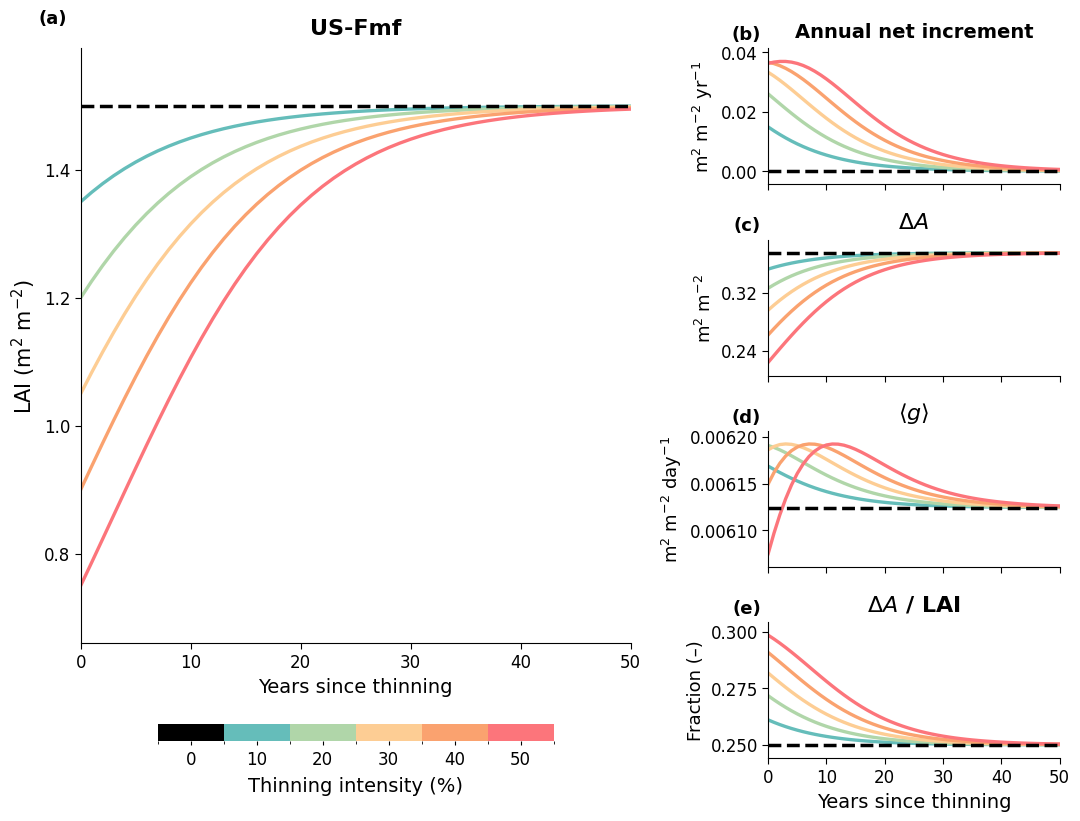

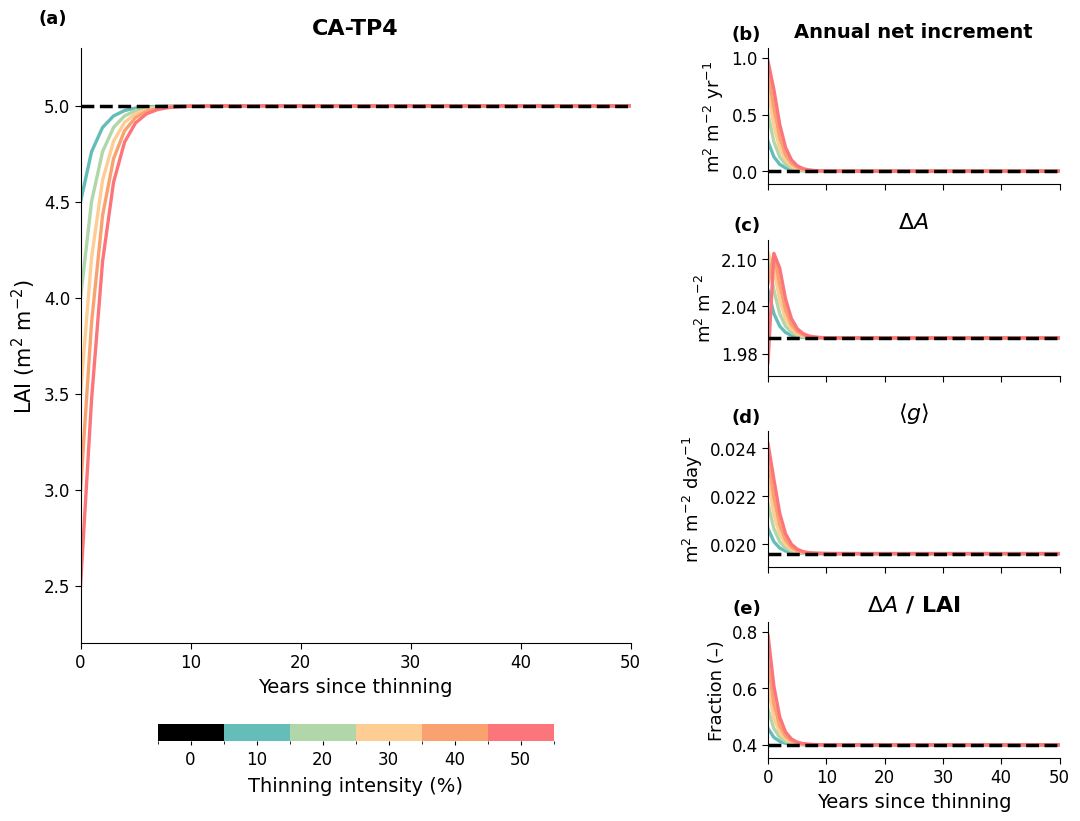

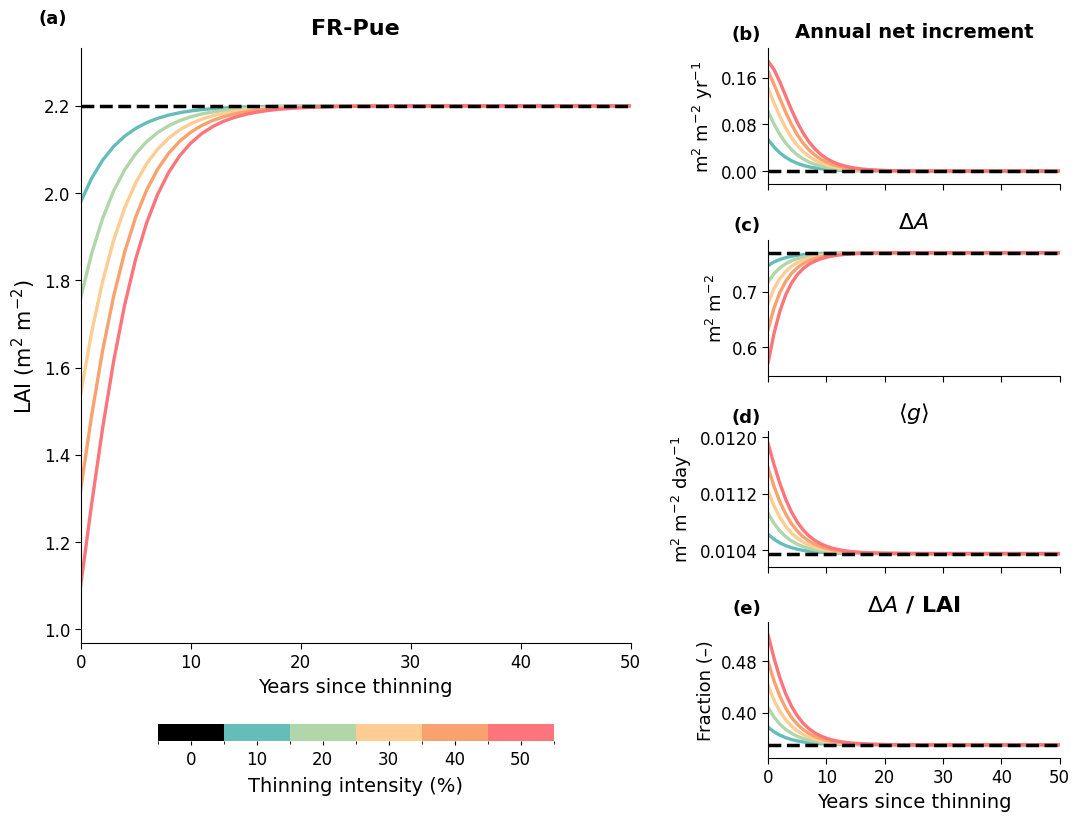

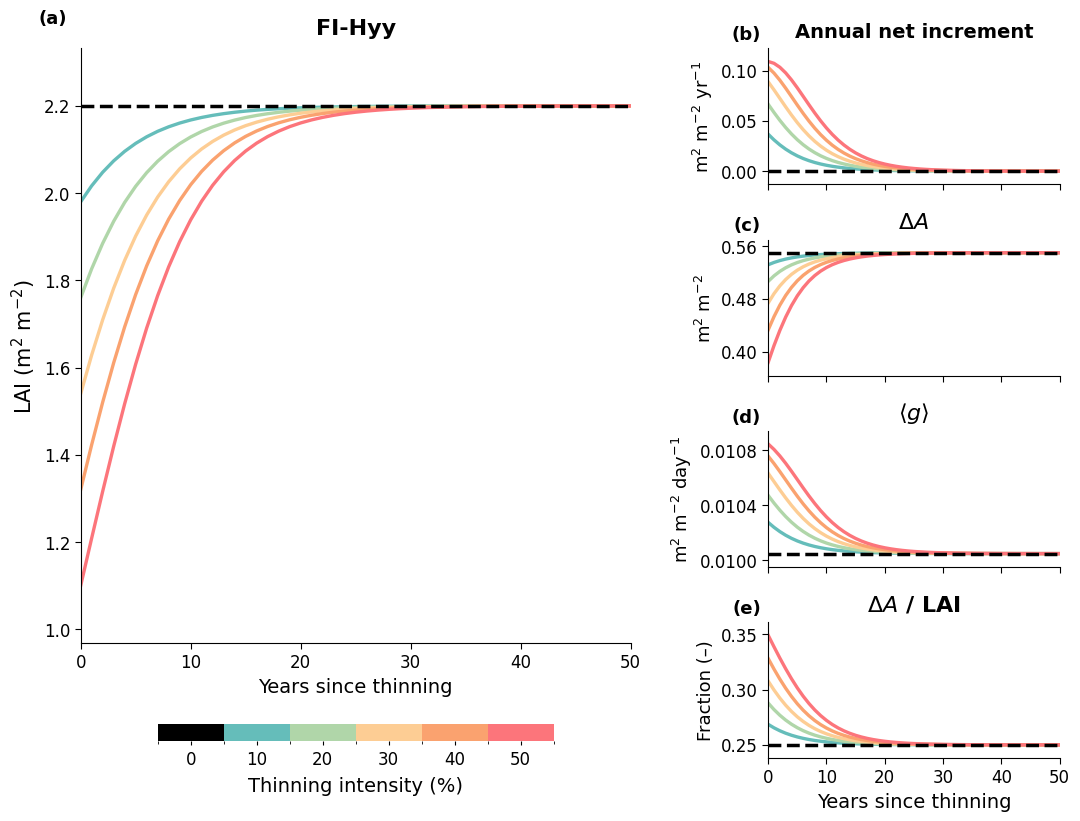

In [8]:

LINE_WIDTH = 2.4
REF_WIDTH = 2.5

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 15,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
})

site_list = list(SITES.keys())


def thinning_percent(scenario):
    match = re.search(r'(\d+(?:\.\d+)?)\s*%', scenario)
    if match is None:
        raise ValueError(f'Cannot read thinning intensity: {scenario}')
    return float(match.group(1))


scenarios = sorted(
    [s for s in COLORS if s != 'Unthinned'],
    key=thinning_percent,
)

levels = np.array(
    [0.0] + [thinning_percent(s) for s in scenarios]
)
scenario_colors = ['black'] + [COLORS[s] for s in scenarios]

midpoints = (levels[:-1] + levels[1:]) / 2
boundaries = np.concatenate([
    [levels[0] - (levels[1] - levels[0]) / 2],
    midpoints,
    [levels[-1] + (levels[-1] - levels[-2]) / 2],
])

cmap = ListedColormap(scenario_colors)
norm = BoundaryNorm(boundaries, cmap.N)

def growth_metrics(d):
    delta_A = d['growth'].to_numpy(dtype=float)
    mean_g = d['mean_g'].to_numpy(dtype=float)
    growth_per_lai = delta_A / d['LAI'].to_numpy(dtype=float)

    return delta_A, mean_g, growth_per_lai


lai_figures = {}

# ------------------------------------------------------------
# (a) LAI
# (b) Annual net increment
# (c) ΔA
# (d) <g>
# (e) ΔA/LAI
# ------------------------------------------------------------
for site_code in site_list:

    fig = plt.figure(figsize=(11, 8.5), layout='none')

    ax_lai = fig.add_axes([0.085, 0.230, 0.500, 0.700])

    right_x = 0.710
    right_width = 0.265
    small_height = 0.160

    ax_net = fig.add_axes([
        right_x, 0.770, right_width, small_height
    ])
    ax_inc = fig.add_axes([
        right_x, 0.545, right_width, small_height
    ], sharex=ax_net)
    ax_g = fig.add_axes([
        right_x, 0.320, right_width, small_height
    ], sharex=ax_net)
    ax_glai = fig.add_axes([
        right_x, 0.095, right_width, small_height
    ], sharex=ax_net)

    cax = fig.add_axes([0.155, 0.115, 0.360, 0.020])

    d_ref = all_results[site_code]['Unthinned']

    # --------------------------------------------------------
    # Unthinned reference
    # --------------------------------------------------------
    ref_A, ref_g, ref_per_lai = growth_metrics(d_ref)

    ref_style = {
        'color': 'black',
        'ls': '--',
        'lw': REF_WIDTH,
        'zorder': 10,
    }

    ax_lai.plot(d_ref['year'], d_ref['LAI'], **ref_style)
    ax_net.plot(d_ref['year'], d_ref['dLAI'], **ref_style)
    ax_inc.plot(d_ref['year'], ref_A, **ref_style)
    ax_g.plot(d_ref['year'], ref_g, **ref_style)
    ax_glai.plot(d_ref['year'], ref_per_lai, **ref_style)

    # --------------------------------------------------------
    # Thinning scenarios
    # --------------------------------------------------------
    for scenario in scenarios:
        d = all_results[site_code][scenario]
        color = COLORS[scenario]

        delta_A, mean_g, per_lai = growth_metrics(d)

        ax_lai.plot(
            d['year'], d['LAI'],
            color=color, lw=LINE_WIDTH,
        )
        ax_net.plot(
            d['year'], d['dLAI'],
            color=color, lw=LINE_WIDTH,
        )
        ax_inc.plot(
            d['year'], delta_A,
            color=color, lw=LINE_WIDTH,
        )
        ax_g.plot(
            d['year'], mean_g,
            color=color, lw=LINE_WIDTH,
        )
        ax_glai.plot(
            d['year'], per_lai,
            color=color, lw=LINE_WIDTH,
        )

    # --------------------------------------------------------
    # Titles and labels
    # --------------------------------------------------------
    ax_lai.set_title(
        site_code,
        fontsize=16,
        fontweight='bold',
        pad=10,
    )
    ax_lai.set_ylabel(r'LAI (m$^2$ m$^{-2}$)', fontsize=15)
    ax_lai.set_xlabel('Years since thinning', fontsize=14)

    ax_net.set_title(
        'Annual net increment',
        fontsize=14,
        fontweight='bold',
        pad=8,
    )
    ax_net.set_ylabel(
        r'm$^2$ m$^{-2}$ yr$^{-1}$',
        fontsize=13,
    )

    ax_inc.set_title(
        r'$\Delta A$',
        fontsize=16,
        fontweight='bold',
        pad=8,
    )
    ax_inc.set_ylabel(r'm$^2$ m$^{-2}$', fontsize=13)

    ax_g.set_title(
        r'$\langle g\rangle$',
        fontsize=16,
        fontweight='bold',
        pad=8,
    )
    ax_g.set_ylabel(
        r'm$^2$ m$^{-2}$ day$^{-1}$',
        fontsize=13,
    )

    ax_glai.set_title(
        r'$\Delta A$ / LAI',
        fontsize=16,
        fontweight='bold',
        pad=8,
    )
    ax_glai.set_ylabel('Fraction (–)', fontsize=13)
    ax_glai.set_xlabel('Years since thinning', fontsize=14)

    for ax in [ax_net, ax_inc, ax_g]:
        ax.tick_params(axis='x', labelbottom=False)

    # --------------------------------------------------------
    # Formatting 
    # --------------------------------------------------------
    axes = [ax_lai, ax_net, ax_inc, ax_g, ax_glai]

    for ax, letter in zip(axes, ['a', 'b', 'c', 'd', 'e']):
        ax.set_xlim(0, N_YEARS)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='both', labelsize=12, length=4)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.margins(y=0.12)

        ax.text(
            -0.025, 1.035,
            f'({letter})',
            transform=ax.transAxes,
            ha='right',
            va='bottom',
            fontsize=13,
            fontweight='bold',
            clip_on=False,
        )

    for ax in [ax_net, ax_inc, ax_g, ax_glai]:
        ax.yaxis.set_major_locator(MaxNLocator(nbins=3))

        formatter = ScalarFormatter(useOffset=False)
        formatter.set_scientific(False)
        ax.yaxis.set_major_formatter(formatter)

    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        cax=cax,
        orientation='horizontal',
        boundaries=boundaries,
        ticks=levels,
        spacing='uniform',
    )
    cbar.set_ticklabels([f'{value:g}' for value in levels])
    cbar.set_label(
        'Thinning intensity (%)',
        fontsize=14,
        labelpad=6,
    )
    cbar.ax.tick_params(labelsize=12, length=3)
    cbar.outline.set_visible(False)

    lai_figures[site_code] = fig

    if SAVE_FIGURES:
        stem = f'Fig4_{site_code.replace("-", "_")}_LAI'
        fig.savefig(
            FIGURE_DIR / f'{stem}.png',
            dpi=200,
            bbox_inches='tight'
        )
        fig.savefig(
            FIGURE_DIR / f'{stem}.pdf',
            bbox_inches='tight'
        )

    plt.show()


## 9. Figure 5. Elasticity 

please refer to Section 2.4 of my thesis about how elasticity is calculated 

In [9]:
ELASTICITY_THINNING = (0.0, 0.3, 0.5)
ELASTICITY_H = 0.001      # 0.1% relative numerical derivative step
ELASTICITY_NBINS = 400    

PARAMETERS = ('Zm', 'RAI', 'Pg50', 'Px50', 'k_xl_max', 'rf_alpha', 'rf_lambda', 'Eo')
OUTPUTS = ('mean_s', 'ET', 'T', 'E')
OUTPUT_LABELS = {
    'mean_s': r'$\langle s\rangle$', 'ET': r'$\langle ET\rangle$',
    'T': r'$\langle T\rangle$', 'E': r'$\langle E\rangle$',
}
PARAM_GROUPS = {
    'Zm': 'Soil / roots', 'RAI': 'Soil / roots',
    'Pg50': 'Plant hydraulics', 'Px50': 'Plant hydraulics',
    'k_xl_max': 'Plant hydraulics',
    'rf_alpha': 'Weather', 'rf_lambda': 'Weather', 'Eo': 'Weather',
}
GROUP_COLORS = {
    'Soil / roots': '#f7c136',
    'Plant hydraulics': '#8ec321',
    'Weather': '#30bbea',
}
PARAM_LABELS = {
    'Zm': r'$Z_m$', 'RAI': 'RAI',
    'Pg50': r'$\psi_{g50}$', 'Px50': r'$\psi_{x50}$',
    'k_xl_max': r'$k_{xl,max}$',
    'rf_alpha': r'$\alpha$', 'rf_lambda': r'$\lambda$', 'Eo': r'$E_0$',
}
HATCHES = {0.0: '', 0.3: '///', 0.5: 'xxx'}

In [10]:
def perturb_for_derivative(params, parameter, fraction):
    new = params.copy()
    new[parameter] *= 1.0 + fraction
    return new


def calculate_local_elasticity(sites, step=0.001, nbins=400):
    results = []
    issues = []
    for site in SITES_ORDER:
        for thinning in ELASTICITY_THINNING:
            lai = sites[site]['ref_LAI'] * (1.0 - thinning)
            baseline_params = parameter_dict(sites[site], lai)
            baseline, _ = hydraulic_outputs(baseline_params, nbins=nbins)

            for parameter in PARAMETERS:
                estimates = {}
                try:
                    # To check numerical stability (if choosing different step size)
                    for h in (step, step / 2):
                        plus, _ = hydraulic_outputs(
                            perturb_for_derivative(baseline_params, parameter, +h),
                            nbins=nbins)
                        minus, _ = hydraulic_outputs(
                            perturb_for_derivative(baseline_params, parameter, -h),
                            nbins=nbins)
                        for metric in OUTPUTS:
                            y0 = baseline[metric]
                            estimates[(h, metric)] = (
                                (plus[metric] - minus[metric]) / (2 * h * y0)
                                if np.isfinite(y0) and abs(y0) > 1e-12 else np.nan
                            )
                except (ValueError, FloatingPointError, ZeroDivisionError, OverflowError) as ex:
                    issues.append(f'{site}, {thinning:.0%}, {parameter}: {ex}')
                    estimates = {(h, out): np.nan
                                 for h in (step, step / 2) for out in OUTPUTS}

                for metric in OUTPUTS:
                    coarse = estimates[(step, metric)]
                    fine = estimates[(step / 2, metric)]
                    stable = np.isclose(coarse, fine, rtol=0.02, atol=0.002)
                    if np.isfinite(coarse) and np.isfinite(fine) and not stable:
                        issues.append(
                            f'{site}, {thinning:.0%}, {parameter}, {metric}: '
                            f'elasticity step check {coarse:.4g} vs {fine:.4g}'
                        )
                    results.append({
                        'Site': site, 'Thinning': thinning,
                        'Parameter': parameter, 'Output': metric,
                        'Elasticity': fine, 'Check_coarse_step': coarse,
                        'Step_stable': bool(stable),
                    })
        print('Elasticity computed:', site)
    return pd.DataFrame(results), issues


elasticity_df, elasticity_issues = calculate_local_elasticity(
    SITES, step=ELASTICITY_H, nbins=ELASTICITY_NBINS)
elasticity_df.to_csv('elasticity_results.csv', index=False)
print('Elasticity values:', len(elasticity_df))
print('Numerical check messages:', len(elasticity_issues))
if elasticity_issues:
    display(pd.DataFrame({'issue': elasticity_issues}).head(30))

display(elasticity_df.head(12).round(5))

Elasticity computed: US-Fmf
Elasticity computed: CA-TP4
Elasticity computed: FR-Pue
Elasticity computed: FI-Hyy
Elasticity values: 384
Numerical check messages: 0


,Site,Thinning,Parameter,Output,Elasticity,Check_coarse_step,Step_stable
0,US-Fmf,0.0,Zm,mean_s,0.01226,0.01226,True
1,US-Fmf,0.0,Zm,ET,0.05134,0.05134,True
2,US-Fmf,0.0,Zm,T,0.09140,0.09140,True
3,US-Fmf,0.0,Zm,E,0.02664,0.02664,True
4,US-Fmf,0.0,RAI,mean_s,-0.00004,-0.00004,True
5,US-Fmf,0.0,RAI,ET,0.00000,0.00000,True
6,US-Fmf,0.0,RAI,T,0.00014,0.00014,True
7,US-Fmf,0.0,RAI,E,-0.00008,-0.00008,True
8,US-Fmf,0.0,Pg50,mean_s,-0.14930,-0.14930,True
9,US-Fmf,0.0,Pg50,ET,0.03054,0.03054,True


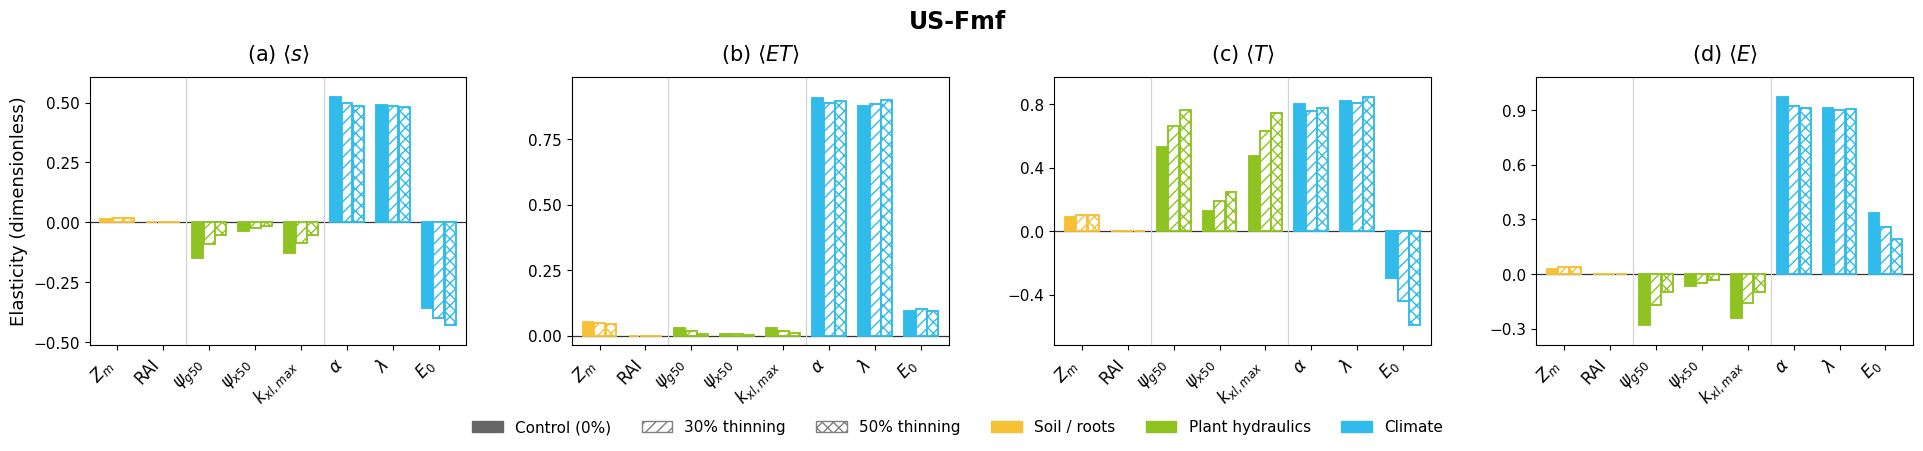

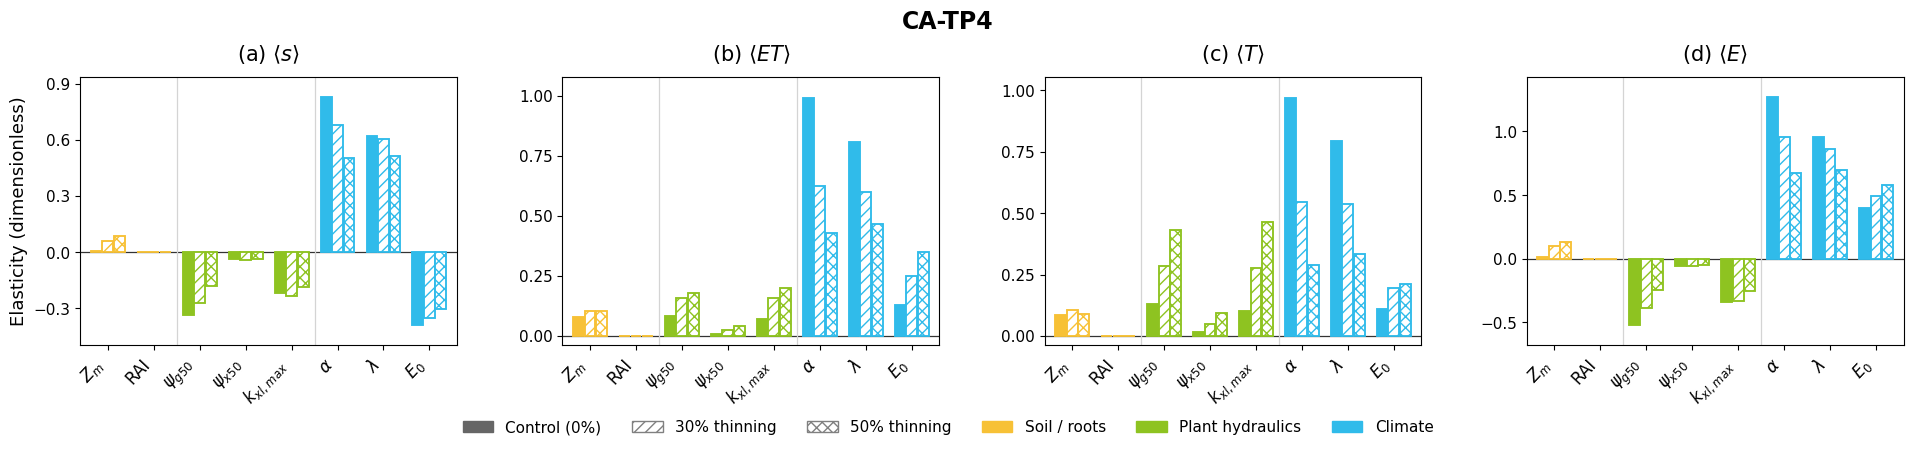

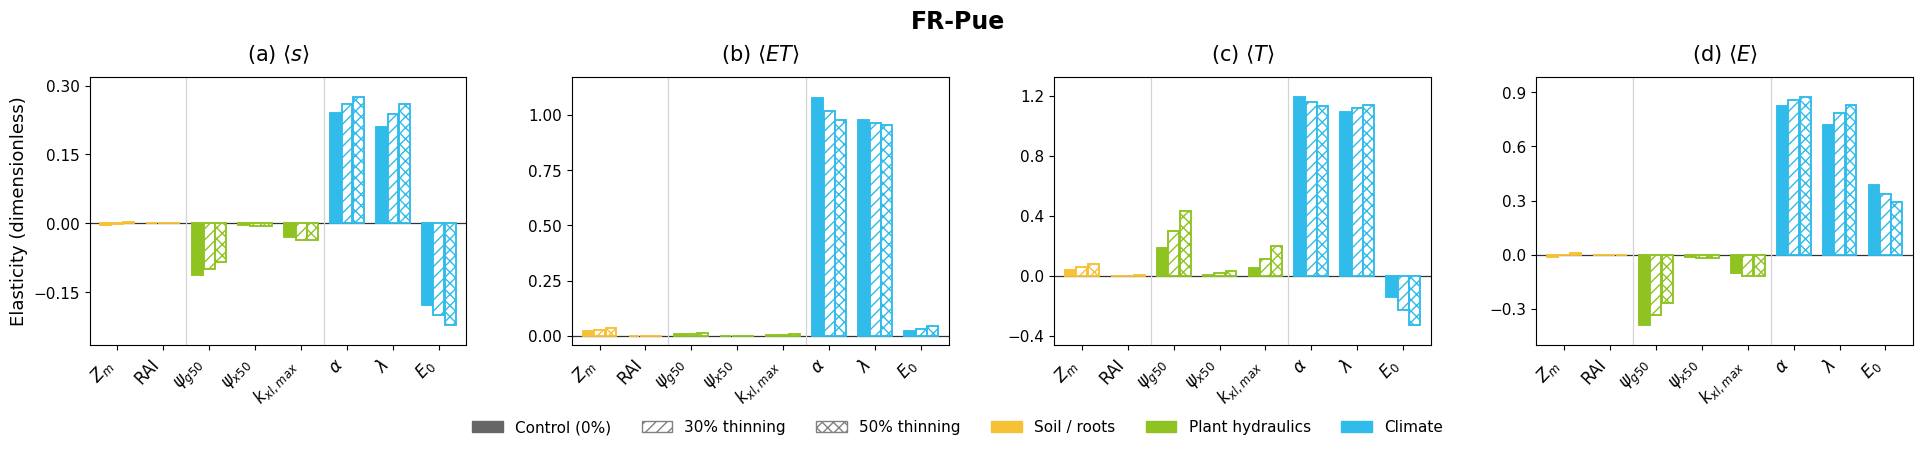

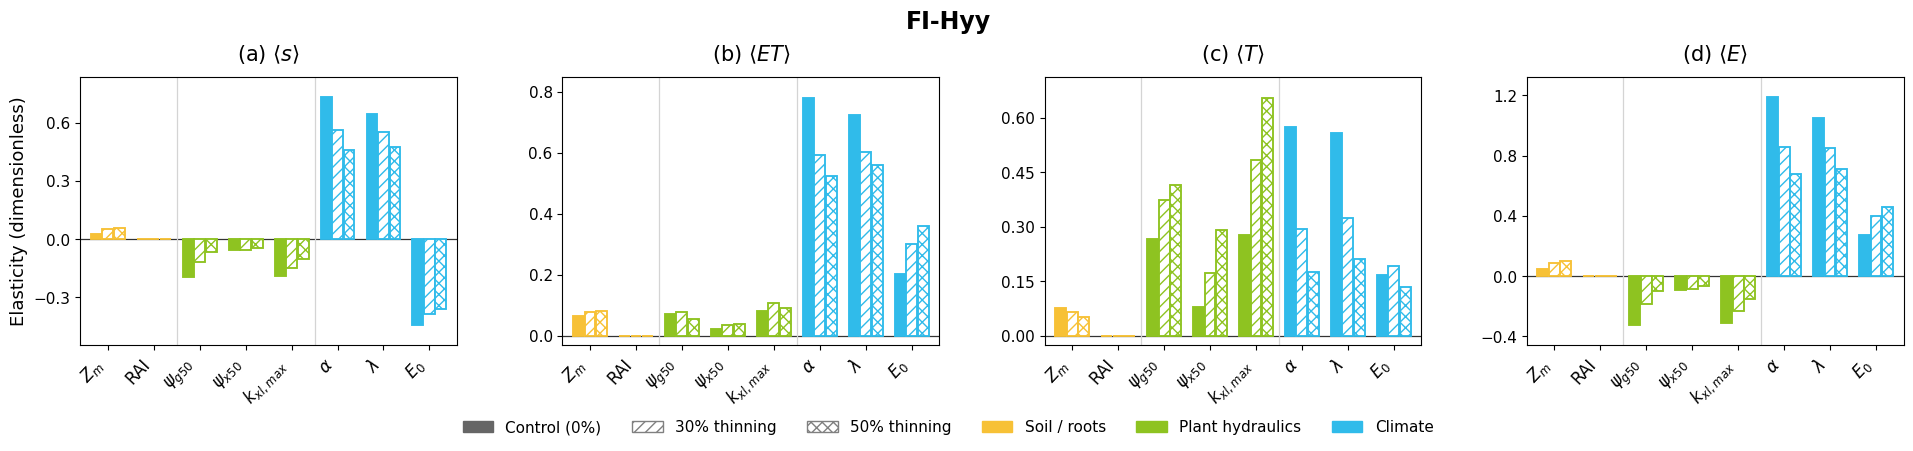

In [11]:

def elasticity_ylim(values, padding=0.09):
    a = np.asarray(values, dtype=float)
    a = a[np.isfinite(a)]
    if not len(a):
        return -0.1, 0.1

    lo, hi = min(0, a.min()), max(0, a.max())
    span = hi - lo

    if span < 1e-12:
        return -0.1, 0.1

    return (
        lo - padding * span if lo < 0 else -0.04 * span,
        hi + padding * span if hi > 0 else 0.04 * span
    )


def plot_elasticity(site, df):

    site_df = df.loc[df['Site'] == site]
    fig, axes = plt.subplots(1, 4, figsize=(19.5, 4.8), sharey=False)

    x = np.arange(len(PARAMETERS))
    bar_width = 0.25
    offsets = {0.0: -bar_width, 0.3: 0.0, 0.5: bar_width}

    titles = {
        'mean_s': r'(a) $\langle s\rangle$',
        'ET': r'(b) $\langle ET\rangle$',
        'T': r'(c) $\langle T\rangle$',
        'E': r'(d) $\langle E\rangle$',
    }

    for ax, output in zip(axes, OUTPUTS):
        sub = site_df.loc[site_df.Output == output]
        lookup = sub.set_index(
            ['Parameter', 'Thinning']
        )['Elasticity']

        values = []

        for thinning in ELASTICITY_THINNING:
            for i, parameter in enumerate(PARAMETERS):

                value = lookup.get((parameter, thinning), np.nan)

                if not np.isfinite(value):
                    continue

                group_color = GROUP_COLORS[PARAM_GROUPS[parameter]]

                ax.bar(
                    i + offsets[thinning],
                    value,
                    width=0.95 * bar_width,
                    facecolor=group_color if thinning == 0 else 'white',
                    edgecolor=group_color,
                    hatch=HATCHES[thinning],
                    linewidth=1.35,
                    zorder=3,
                )

                values.append(value)

        ax.axhline(0, color='#333333', lw=0.9)
        ax.axvline(1.5, color='0.83', lw=0.9)
        ax.axvline(4.5, color='0.83', lw=0.9)

        ax.set_xticks(
            x,
            [PARAM_LABELS[p] for p in PARAMETERS],
            rotation=47,
            ha='right',
            fontsize=12
        )

        ax.set_ylim(*elasticity_ylim(values))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.set_title(titles[output], fontsize=15, pad=12)
        ax.tick_params(axis='y', labelsize=11)
        ax.set_xlim(-0.6, len(PARAMETERS) - 0.4)

    axes[0].set_ylabel(
        'Elasticity (dimensionless)', fontsize=13
    )

    fig.suptitle(site, fontsize=17, weight='bold', y=0.98)

    keys = [
        Patch(
            facecolor='#666', edgecolor='#666',
            label='Control (0%)'
        ),
        Patch(
            facecolor='white', edgecolor='0.5',
            hatch='///', label='30% thinning'
        ),
        Patch(
            facecolor='white', edgecolor='0.5',
            hatch='xxx', label='50% thinning'
        ),
    ] + [
        Patch(
            facecolor=c,
            edgecolor=c,
            label='Climate' if name == 'Weather' else name
        )
        for name, c in GROUP_COLORS.items()
    ]

    fig.legend(
        handles=keys,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.065),
        ncol=6,
        frameon=False,
        fontsize=11
    )

    fig.subplots_adjust(
        left=0.055,
        right=0.99,
        bottom=0.28,
        top=0.84,
        wspace=0.28
    )

    return fig


for site in SITES_ORDER:
    fig = plot_elasticity(site, elasticity_df)

    if SAVE_FIGURES:
        stem = f'Fig5_{site.replace("-", "_")}_Elasticity'
        fig.savefig(
            FIGURE_DIR / f'{stem}.png',
            dpi=200,
            bbox_inches='tight'
        )
        fig.savefig(
            FIGURE_DIR / f'{stem}.pdf',
            bbox_inches='tight'
        )

    plt.show()
